<a href="https://colab.research.google.com/github/itsbhh/Smart_Education_System/blob/main/Smart_Education_System.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Smart Education System
## Student Failure-Risk Prediction Using Data Mining

**Platform:** Google Colab  
**Algorithm:** Decision Tree Classification  
**Dataset:** 400 synthetic students, with an optional 401st new-student record

This notebook will:
1. Create and show the 400-student dataset.
2. Train a Decision Tree model and evaluate it.
3. Calculate a predicted result, failure probability and LOW/MEDIUM/HIGH risk level for every student.
4. Show a risk summary and the complete 400-row dataset in the output.
5. Let you enter a new student (for example, Student 401).
6. Show the complete updated 401-row dataset in the output.
7. Ask whether you want to download the 401-row dataset.

> The 400 records are synthetic examples for a college project. Predictions and probability scores are demonstrations, not verified real-world failure probabilities. Use them only to guide supportive teacher review.

## 1. Install and import libraries

In [1]:
!pip -q install pandas numpy scikit-learn matplotlib seaborn joblib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

print("Libraries imported successfully!")


Libraries imported successfully!


## 2. Create the 400-student dataset
Each student has a name and four academic attributes. The `Exam_Result` column shows **Fail** or **Do not fail**.

In [2]:
rng = np.random.default_rng(42)
n = 400

attendance = np.clip(rng.normal(78, 13, n), 25, 100)
internal = np.clip(rng.normal(20, 6, n), 0, 30)
assignment = np.clip(rng.normal(14, 4, n), 0, 20)
previous = np.clip(rng.normal(65, 18, n), 0, 100)

# Illustrative rule used only to create sample outcomes
risk_score = (
    0.30 * (100 - attendance) / 100 +
    0.30 * (30 - internal) / 30 +
    0.20 * (20 - assignment) / 20 +
    0.20 * (100 - previous) / 100
)
noise = rng.normal(0, 0.07, n)
failed = ((risk_score + noise) > 0.43).astype(int)

df = pd.DataFrame({
    "Student_Name": [f"Student {i}" for i in range(1, n + 1)],
    "Attendance_Percentage": attendance.round(1),
    "Internal_Marks_Out_Of_30": internal.round(1),
    "Assignment_Score_Out_Of_20": assignment.round(1),
    "Previous_Performance_Percentage": previous.round(1),
    "Failed_Next_Exam": failed
})

# Human-readable result column requested
df["Exam_Result"] = df["Failed_Next_Exam"].map({
    0: "Do not fail",
    1: "Fail"
})

print("Dataset created:", len(df), "students")
print("Columns:", list(df.columns))


Dataset created: 400 students
Columns: ['Student_Name', 'Attendance_Percentage', 'Internal_Marks_Out_Of_30', 'Assignment_Score_Out_Of_20', 'Previous_Performance_Percentage', 'Failed_Next_Exam', 'Exam_Result']


## 3. Show the result summary for all 400 students

ACTUAL/LABELLED RESULT SUMMARY FOR 400 SYNTHETIC STUDENTS
---------------------------------------------------------


,Exam_Result,Number_of_Students
0,Fail,46
1,Do not fail,354


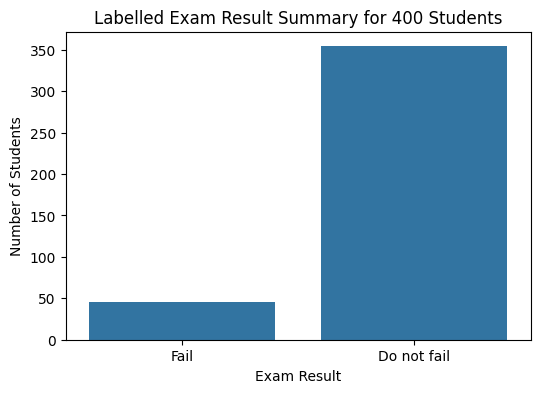

In [3]:
result_counts = df["Exam_Result"].value_counts().reindex(
    ["Fail", "Do not fail"], fill_value=0
)

print("ACTUAL/LABELLED RESULT SUMMARY FOR 400 SYNTHETIC STUDENTS")
print("---------------------------------------------------------")
display(result_counts.rename_axis("Exam_Result").reset_index(name="Number_of_Students"))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Exam_Result", order=["Fail", "Do not fail"])
plt.title("Labelled Exam Result Summary for 400 Students")
plt.xlabel("Exam Result")
plt.ylabel("Number of Students")
plt.show()

## 4. Preview the 400-student dataset before modelling
The risk probability and predicted-risk columns will be added after the model is trained.

In [4]:
print("INITIAL DATASET: ALL 400 STUDENTS")
pd.set_option("display.max_rows", 500)
pd.set_option("display.max_columns", None)
display(df)

INITIAL DATASET: ALL 400 STUDENTS


,Student_Name,Attendance_Percentage,Internal_Marks_Out_Of_30,Assignment_Score_Out_Of_20,Previous_Performance_Percentage,Failed_Next_Exam,Exam_Result
0,Student 1,82.0,18.9,10.6,41.2,0,Do not fail
1,Student 2,64.5,21.2,9.7,56.2,1,Fail
2,Student 3,87.8,24.9,15.4,72.6,0,Do not fail
3,Student 4,90.2,17.6,15.5,63.2,0,Do not fail
4,Student 5,52.6,23.1,19.1,53.3,0,Do not fail
5,Student 6,61.1,18.4,18.4,52.9,1,Fail
6,Student 7,79.7,19.3,13.5,52.2,0,Do not fail
7,Student 8,73.9,25.0,9.0,49.2,0,Do not fail
8,Student 9,77.8,8.0,12.7,100.0,0,Do not fail
9,Student 10,66.9,12.2,14.9,70.4,0,Do not fail


## 5. Prepare data and train the Decision Tree model

In [5]:
# Model training uses the four academic attributes only.
# Student_Name and Exam_Result are not model input features.

## 6. Calculate failure probability, predicted result and risk level for all 400 students

In [6]:
FEATURES = [
    "Attendance_Percentage",
    "Internal_Marks_Out_Of_30",
    "Assignment_Score_Out_Of_20",
    "Previous_Performance_Percentage"
]
TARGET = "Failed_Next_Exam"

X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)
model.fit(X_train, y_train)

print("Model trained successfully!")
print("Training students:", len(X_train))
print("Testing students:", len(X_test))


Model trained successfully!
Training students: 300
Testing students: 100


RISK SUMMARY FOR ALL 400 STUDENTS
---------------------------------


,Risk_Level,Number_of_Students
0,LOW,304
1,MEDIUM,12
2,HIGH,84



PREDICTED EXAM RESULT SUMMARY


,Predicted_Exam_Result,Number_of_Students
0,Fail,96
1,Do not fail,304


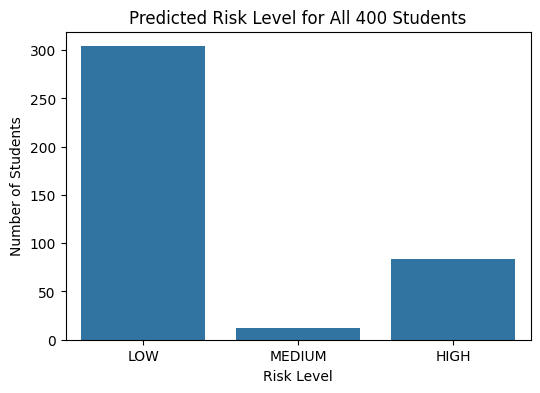


COMPLETE DATASET WITH PREDICTION AND RISK: ALL 400 STUDENTS


,Student_Name,Attendance_Percentage,Internal_Marks_Out_Of_30,Assignment_Score_Out_Of_20,Previous_Performance_Percentage,Failed_Next_Exam,Exam_Result,Predicted_Exam_Result,Estimated_Failure_Probability_Percent,Risk_Level
0,Student 1,82.0,18.9,10.6,41.2,0,Do not fail,Do not fail,0.00,LOW
1,Student 2,64.5,21.2,9.7,56.2,1,Fail,Fail,86.65,HIGH
2,Student 3,87.8,24.9,15.4,72.6,0,Do not fail,Do not fail,0.00,LOW
3,Student 4,90.2,17.6,15.5,63.2,0,Do not fail,Do not fail,0.00,LOW
4,Student 5,52.6,23.1,19.1,53.3,0,Do not fail,Do not fail,0.00,LOW
5,Student 6,61.1,18.4,18.4,52.9,1,Fail,Fail,86.65,HIGH
6,Student 7,79.7,19.3,13.5,52.2,0,Do not fail,Do not fail,0.00,LOW
7,Student 8,73.9,25.0,9.0,49.2,0,Do not fail,Do not fail,0.00,LOW
8,Student 9,77.8,8.0,12.7,100.0,0,Do not fail,Do not fail,0.00,LOW
9,Student 10,66.9,12.2,14.9,70.4,0,Do not fail,Do not fail,0.00,LOW


In [7]:
# Calculate model predictions and estimated failure probabilities for ALL 400 records.
all_probabilities = model.predict_proba(df[FEATURES])[:, list(model.classes_).index(1)] * 100
all_predictions = model.predict(df[FEATURES])

risk_df = df.copy()
risk_df["Predicted_Exam_Result"] = np.where(
    all_predictions == 1, "Fail", "Do not fail"
)
risk_df["Estimated_Failure_Probability_Percent"] = np.round(all_probabilities, 2)
risk_df["Risk_Level"] = np.select(
    [all_probabilities < 35, all_probabilities < 65],
    ["LOW", "MEDIUM"],
    default="HIGH"
)

print("RISK SUMMARY FOR ALL 400 STUDENTS")
print("---------------------------------")
risk_summary = (
    risk_df["Risk_Level"]
    .value_counts()
    .reindex(["LOW", "MEDIUM", "HIGH"], fill_value=0)
    .rename_axis("Risk_Level")
    .reset_index(name="Number_of_Students")
)
display(risk_summary)

print("\nPREDICTED EXAM RESULT SUMMARY")
display(
    risk_df["Predicted_Exam_Result"]
    .value_counts()
    .reindex(["Fail", "Do not fail"], fill_value=0)
    .rename_axis("Predicted_Exam_Result")
    .reset_index(name="Number_of_Students")
)

plt.figure(figsize=(6, 4))
sns.countplot(data=risk_df, x="Risk_Level", order=["LOW", "MEDIUM", "HIGH"])
plt.title("Predicted Risk Level for All 400 Students")
plt.xlabel("Risk Level")
plt.ylabel("Number of Students")
plt.show()

print("\nCOMPLETE DATASET WITH PREDICTION AND RISK: ALL 400 STUDENTS")
pd.set_option("display.max_rows", 500)
pd.set_option("display.max_columns", None)
display(risk_df)


## 7. Evaluate the model

Accuracy : 0.730
Precision: 0.192
Recall   : 0.455
F1-score : 0.270

Classification report:
              precision    recall  f1-score   support

           0       0.92      0.76      0.83        89
           1       0.19      0.45      0.27        11

    accuracy                           0.73       100
   macro avg       0.56      0.61      0.55       100
weighted avg       0.84      0.73      0.77       100



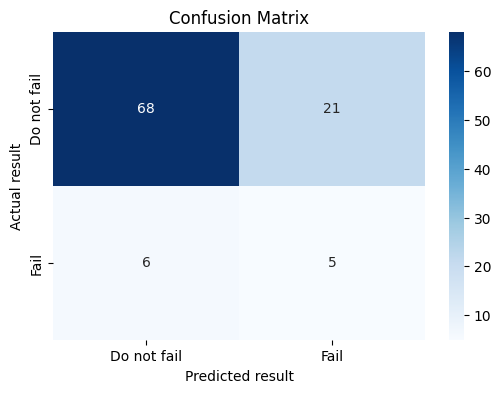

In [8]:
y_pred = model.predict(X_test)

print(f"Accuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.3f}")
print(f"Recall   : {recall_score(y_test, y_pred, zero_division=0):.3f}")
print(f"F1-score : {f1_score(y_test, y_pred, zero_division=0):.3f}")

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Do not fail", "Fail"],
    yticklabels=["Do not fail", "Fail"]
)
plt.xlabel("Predicted result")
plt.ylabel("Actual result")
plt.title("Confusion Matrix")
plt.show()


## 8. Visualize the Decision Tree

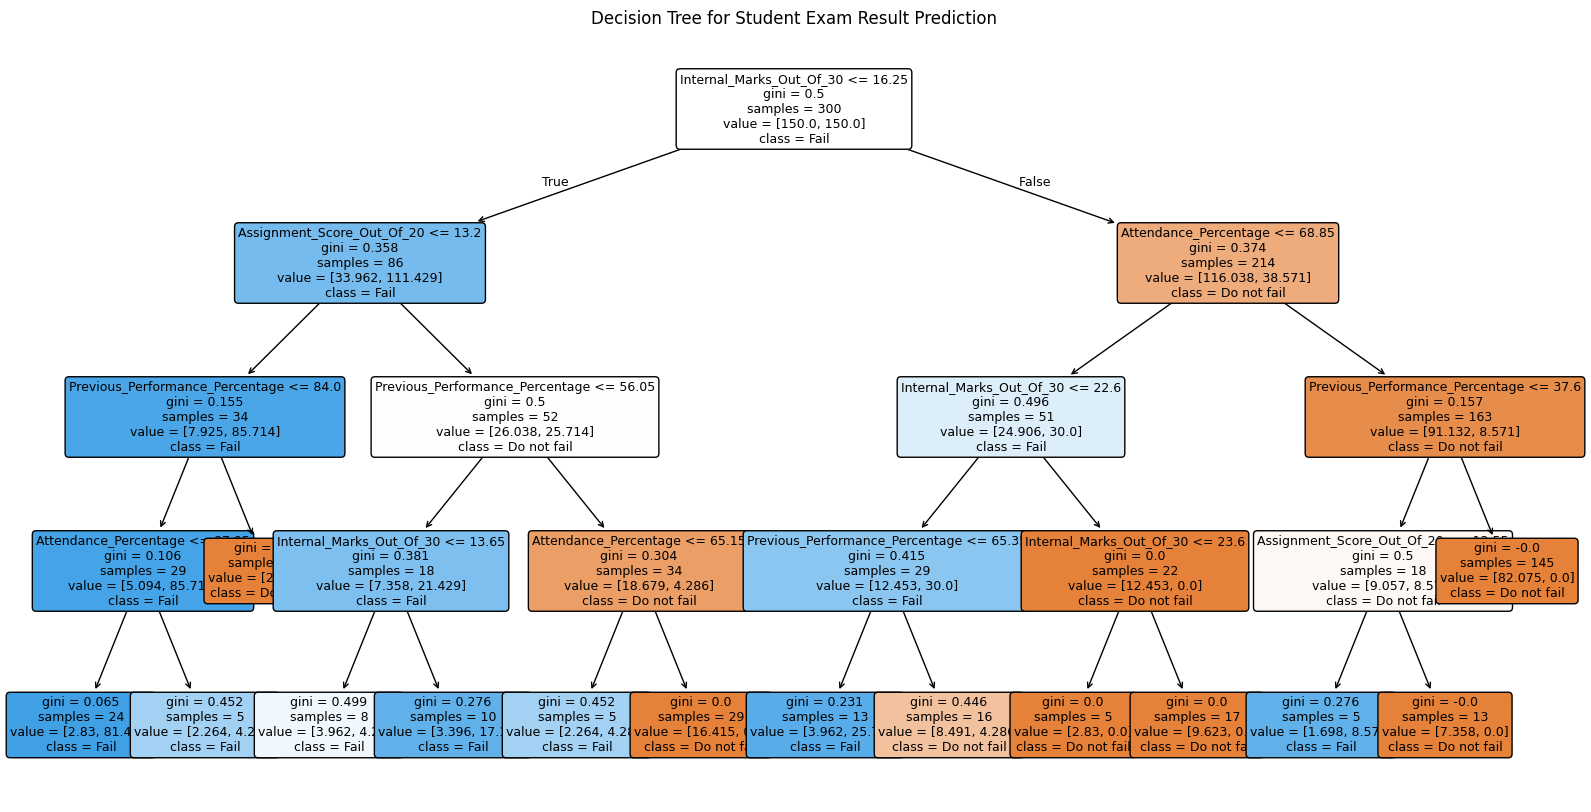

In [9]:
plt.figure(figsize=(20, 10))
plot_tree(
    model,
    feature_names=FEATURES,
    class_names=["Do not fail", "Fail"],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Decision Tree for Student Exam Result Prediction")
plt.show()


## 9. Enter details for a NEW student (Student 401) and predict

Run this cell and type the student's details when prompted.  
Valid ranges:
- Attendance: 0 to 100
- Internal marks: 0 to 30
- Assignment score: 0 to 20
- Previous performance: 0 to 100

In [10]:
# Enter new student details here when prompted.
new_name = input("Enter student name (example: Student 401): ").strip()
if not new_name:
    new_name = "Student 401"

new_attendance = float(input("Enter attendance percentage (0-100): "))
new_internal = float(input("Enter internal marks out of 30 (0-30): "))
new_assignment = float(input("Enter assignment score out of 20 (0-20): "))
new_previous = float(input("Enter previous performance percentage (0-100): "))

new_values = {
    "Attendance_Percentage": new_attendance,
    "Internal_Marks_Out_Of_30": new_internal,
    "Assignment_Score_Out_Of_20": new_assignment,
    "Previous_Performance_Percentage": new_previous
}

valid_ranges = {
    "Attendance_Percentage": (0, 100),
    "Internal_Marks_Out_Of_30": (0, 30),
    "Assignment_Score_Out_Of_20": (0, 20),
    "Previous_Performance_Percentage": (0, 100)
}

for column, value in new_values.items():
    low, high = valid_ranges[column]
    if not low <= value <= high:
        raise ValueError(f"{column} must be between {low} and {high}.")

new_student = pd.DataFrame([new_values], columns=FEATURES)

failure_probability = model.predict_proba(new_student)[0][
    list(model.classes_).index(1)
]
predicted_class = int(model.predict(new_student)[0])
predicted_result = "Fail" if predicted_class == 1 else "Do not fail"

if failure_probability >= 0.65:
    risk_level = "HIGH"
    suggestion = "Arrange a teacher meeting, attendance follow-up and focused remedial support."
elif failure_probability >= 0.35:
    risk_level = "MEDIUM"
    suggestion = "Monitor progress and provide targeted practice."
else:
    risk_level = "LOW"
    suggestion = "Continue regular academic support."

print("\nNEW STUDENT PREDICTION")
print("----------------------")
print("Student name:", new_name)
display(new_student)
print("Predicted exam result:", predicted_result)
print(f"Estimated failure probability: {failure_probability * 100:.1f}%")
print("Risk level:", risk_level)
print("Suggested support:", suggestion)
print("\nNote: This is a model prediction, not the student's confirmed exam result.")


Enter student name (example: Student 401): student 401
Enter attendance percentage (0-100): 100
Enter internal marks out of 30 (0-30): 20
Enter assignment score out of 20 (0-20): 10
Enter previous performance percentage (0-100): 88

NEW STUDENT PREDICTION
----------------------
Student name: student 401


,Attendance_Percentage,Internal_Marks_Out_Of_30,Assignment_Score_Out_Of_20,Previous_Performance_Percentage
0,100.0,20.0,10.0,88.0


Predicted exam result: Do not fail
Estimated failure probability: 0.0%
Risk level: LOW
Suggested support: Continue regular academic support.

Note: This is a model prediction, not the student's confirmed exam result.


## 10. Add Student 401 and show the complete updated 401-row dataset
This cell appends the new student's prediction to the 400 students. The actual exam result for Student 401 remains `Not yet known`.

In [11]:
# Create the export row for Student 401.
new_export_row = {
    "Student_Name": new_name,
    "Attendance_Percentage": new_attendance,
    "Internal_Marks_Out_Of_30": new_internal,
    "Assignment_Score_Out_Of_20": new_assignment,
    "Previous_Performance_Percentage": new_previous,
    "Failed_Next_Exam": np.nan,
    "Exam_Result": "Not yet known",
    "Predicted_Exam_Result": predicted_result,
    "Estimated_Failure_Probability_Percent": round(failure_probability * 100, 2),
    "Risk_Level": risk_level
}

# Start with the complete 400-student dataset INCLUDING calculated risk columns.
updated_df = risk_df.copy()

# Append Student 401. Its actual exam result is unknown until the exam happens.
updated_df = pd.concat(
    [updated_df, pd.DataFrame([new_export_row])],
    ignore_index=True
)

print("UPDATED DATASET: ALL 401 STUDENTS (400 EXISTING + NEW STUDENT)")
print("-------------------------------------------------------------")
print("Total records:", len(updated_df))
display(updated_df)

UPDATED DATASET: ALL 401 STUDENTS (400 EXISTING + NEW STUDENT)
-------------------------------------------------------------
Total records: 401


,Student_Name,Attendance_Percentage,Internal_Marks_Out_Of_30,Assignment_Score_Out_Of_20,Previous_Performance_Percentage,Failed_Next_Exam,Exam_Result,Predicted_Exam_Result,Estimated_Failure_Probability_Percent,Risk_Level
0,Student 1,82.0,18.9,10.6,41.2,0.0,Do not fail,Do not fail,0.00,LOW
1,Student 2,64.5,21.2,9.7,56.2,1.0,Fail,Fail,86.65,HIGH
2,Student 3,87.8,24.9,15.4,72.6,0.0,Do not fail,Do not fail,0.00,LOW
3,Student 4,90.2,17.6,15.5,63.2,0.0,Do not fail,Do not fail,0.00,LOW
4,Student 5,52.6,23.1,19.1,53.3,0.0,Do not fail,Do not fail,0.00,LOW
5,Student 6,61.1,18.4,18.4,52.9,1.0,Fail,Fail,86.65,HIGH
6,Student 7,79.7,19.3,13.5,52.2,0.0,Do not fail,Do not fail,0.00,LOW
7,Student 8,73.9,25.0,9.0,49.2,0.0,Do not fail,Do not fail,0.00,LOW
8,Student 9,77.8,8.0,12.7,100.0,0.0,Do not fail,Do not fail,0.00,LOW
9,Student 10,66.9,12.2,14.9,70.4,0.0,Do not fail,Do not fail,0.00,LOW


### Optional: download the updated 401-student dataset

In [14]:
# Choose YES when you want to download the 401-row dataset.
download_choice = input("Do you want to download the updated 401-student dataset? (yes/no): ").strip().lower()

if download_choice in ["yes", "y"]:
    from google.colab import files
    updated_filename = "smart_education_dataset_with_401_students.csv"
    updated_df.to_csv(updated_filename, index=False)
    files.download(updated_filename)
    print("Download started:", updated_filename)
else:
    print("Download skipped. The complete 401-row dataset is already displayed above.")

Do you want to download the updated 401-student dataset? (yes/no): yes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started: smart_education_dataset_with_401_students.csv


## 11. Save the trained model

In [13]:
joblib.dump(model, "student_risk_model.joblib")
print("Trained model saved as student_risk_model.joblib")


Trained model saved as student_risk_model.joblib


## Conclusion

This notebook creates 400 synthetic student records, trains a Decision Tree classifier, calculates predicted exam results and estimated failure probabilities, assigns LOW/MEDIUM/HIGH risk levels, and displays the risk summary and complete 400-row dataset. You can enter a new student (Student 401), view the complete updated 401-row dataset, and choose whether to download it as a CSV. Student 401's actual exam result remains `Not yet known`.

The dataset is synthetic. For real institutional use, obtain appropriate authorization, protect student privacy, validate the model on representative data, check for bias and ensure predictions are used only to offer support with teacher review.